# Sesión de clase 14 · Ejercicio 1: RAG sobre la Tienda Virtual

**Contexto:** la Tienda Virtual quiere un asistente que responda preguntas de clientes y analistas
("¿qué audífonos con cancelación de ruido tienen?", "¿de qué se quejan en las entregas?").
Un modelo de lenguaje (LLM) por sí solo no conoce el catálogo de la tienda: lo que sabe viene de su
entrenamiento. **RAG** (*Retrieval-Augmented Generation*) resuelve esto recuperando primero los
documentos relevantes y entregándoselos al modelo como contexto.

**Datos** (scrapeados de la Tienda Virtual y copiados en `../data/`):
- `productos.csv` — 90 productos (9 categorías × 10) con descripción, precio, stock y calificación.
- `resenas_entrega.csv` — 110 reseñas post-compra con calificación 1–5★.
- `comentarios.csv` — 135 testimonios generales de clientes.
- `clientes.csv` — 120 clientes de 7 países (se usa solo el país).
- `preguntas_prueba.csv` — banco de 10 preguntas con la respuesta esperada; se usa en todos los ejercicios.

**Modelos** (locales, CPU): `paraphrase-multilingual-MiniLM-L12-v2` (embeddings) y `Qwen/Qwen2.5-0.5B-Instruct` (LLM).

**Etapas:** LLM sin contexto · indexación en ChromaDB · recuperación con filtros · generación aumentada ·
búsqueda por palabras clave · **comparación: sin RAG vs. con RAG**.

## 0. Configuración

In [1]:
import os, warnings
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"; os.environ["TOKENIZERS_PARALLELISM"] = "false"
warnings.filterwarnings("ignore")
import re, sys, time, unicodedata
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import chromadb
from chromadb.utils import embedding_functions
from transformers import AutoTokenizer, AutoModelForCausalLM

sys.path.append("..")              # para importar comparacion.py de la raíz de la sesión
import comparacion as cmp
import transformers; transformers.logging.set_verbosity_error(); transformers.logging.disable_progress_bar()

DATA = Path("../data")
BDV = Path("../bdv")               # base vectorial persistente (la reutilizan los ejercicios 2, 3 y 4)
MODELO_EMB = "paraphrase-multilingual-MiniLM-L12-v2"
MODELO_LLM = "Qwen/Qwen2.5-0.5B-Instruct"   # cambiar a "Qwen/Qwen2.5-1.5B-Instruct" si la máquina lo permite

pd.set_option("display.max_colwidth", 120)
torch.manual_seed(0)

## 1. Cargar los datos scrapeados

In [3]:
productos = pd.read_csv(DATA / "productos.csv")
resenas = pd.read_csv(DATA / "resenas_entrega.csv")
testimonios = pd.read_csv(DATA / "comentarios.csv")
clientes = pd.read_csv(DATA / "clientes.csv")
banco = cmp.cargar_banco()

print(f"productos={len(productos)}  resenas_entrega={len(resenas)}  testimonios={len(testimonios)}  clientes={len(clientes)}")
productos[["codigo", "nombre", "categoria", "subcategoria", "precio", "stock", "calificacion_promedio"]].head()

productos=90  resenas_entrega=110  testimonios=135  clientes=120


,codigo,nombre,categoria,subcategoria,precio,stock,calificacion_promedio
0,PROD-001,Apple iPhone 15 Pro Max 256GB,Smartphones,Gama Alta,5599,18,3.5
1,PROD-002,Apple iPhone 15 128GB,Smartphones,Gama Alta,3799,25,3.3
2,PROD-003,Samsung Galaxy S24 Ultra 512GB,Smartphones,Gama Alta,5299,15,3.3
3,PROD-004,Samsung Galaxy A55 128GB,Smartphones,Gama Media,1399,40,3.0
4,PROD-005,Xiaomi Redmi Note 13 Pro 256GB,Smartphones,Gama Media,999,45,2.8


In [3]:
banco[["id", "tipo", "pregunta", "respuesta_referencia"]]

,id,tipo,pregunta,respuesta_referencia
0,1,descriptiva,¿Qué audífonos con cancelación de ruido vende la tienda?,"Sony WH-1000XM5, Bose QuietComfort Ultra, AirPods Pro 2, Galaxy Buds2 Pro y Sennheiser Momentum 4"
1,2,filtro,¿Qué smartwatches cuestan menos de 1000 soles?,Amazfit GTS 4 Mini (S/ 449) y Huawei Watch GT 4 (S/ 999)
2,3,conteo,¿Cuántos productos tienen stock menor a 5 unidades?,2 productos: DJI Air 3 (4) y Samsung Family Hub (3)
3,4,agregacion,¿Cuál es la calificación promedio de los productos de la categoría Audio?,3.44 (promedio de 10 productos)
4,5,ranking,¿Qué país tiene el mayor monto total de ventas?,"Perú, con S/ 2 011 695.86"
5,6,opinion,¿De qué se quejan los clientes en las reseñas de entrega?,"Retrasos en la entrega, productos que llegan usados o dañados y accesorios faltantes"
6,7,puntual,¿Cuál es el precio del Nintendo Switch OLED?,S/ 1599
7,8,relacional,¿Qué productos recibieron reseñas de entrega negativas de clientes de Chile?,"Sennheiser Momentum 4, Garmin Forerunner 265, OnePlus 12 y HP Pavilion 15"
8,9,ranking,¿Cuál es el producto mejor calificado de la categoría Fotografia y Video?,Insta360 X4 (5.0)
9,10,en_vivo,¿Cuánto stock queda ahora del DJI Air 3?,Depende de la tienda en este momento (4 en los datos scrapeados)


## 2. Punto de partida: LLM sin contexto

Un LLM genera texto prediciendo el siguiente *token* a partir de lo que aprendió en su entrenamiento
(**conocimiento paramétrico**). No sabe nada de los precios, el stock ni las reseñas de esta tienda.
Cuando se le pregunta algo que no sabe puede negarse o, peor, **alucinar**: inventar una respuesta
con apariencia plausible.

Se usa decodificación *greedy* (`do_sample=False`): el modelo siempre elige el token más probable,
así la misma entrada produce la misma salida.

In [7]:
tokenizer = AutoTokenizer.from_pretrained(MODELO_LLM)
llm = AutoModelForCausalLM.from_pretrained(MODELO_LLM, dtype=torch.float32)
llm.eval()

def generar(mensajes, max_new_tokens=220):
    entrada = tokenizer.apply_chat_template(mensajes, add_generation_prompt=True,
                                            return_tensors="pt", return_dict=True)
    with torch.no_grad():
        salida = llm.generate(**entrada, max_new_tokens=max_new_tokens, do_sample=False)
    return tokenizer.decode(salida[0][entrada["input_ids"].shape[1]:], skip_special_tokens=True).strip()

SISTEMA = "Eres el asistente de 'Mi Tienda Virtual', una tienda peruana de tecnología. Responde en español, en pocas frases."

def responder_sin_rag(pregunta):
    return generar([{"role": "system", "content": SISTEMA},
                    {"role": "user", "content": pregunta}])

for p in ["¿Cuál es el precio del Nintendo Switch OLED?",
          "¿Qué smartwatches cuestan menos de 1000 soles?"]:
    print("❓", p, "\n🤖", responder_sin_rag(p), "\n")

❓ ¿Cuál es el precio del Nintendo Switch OLED? 
🤖 El Nintendo Switch OLED tiene un precio de $199. 

❓ ¿Qué smartwatches cuestan menos de 1000 soles? 
🤖 Los smartwatches más baratos son los de la marca Garmin, que costan entre 950 y 1200 soles. También puedes encontrar modelos de Apple o Huawei a menudo más económicos. 



El modelo no tiene forma de conocer los precios reales de la tienda. Lo que responde viene de su
entrenamiento (o lo inventa).

## 3. Indexación: de documentos a vectores

RAG tiene dos fases:

1. **Indexación** (una vez): se convierten los documentos en *embeddings* y se guardan en una base vectorial.
2. **Consulta** (cada pregunta): se recuperan los *k* documentos más cercanos a la pregunta y se le pasan al LLM.

### 3.1 Construcción de documentos (*chunking*)

El *chunk* es la unidad que se recupera. Aquí el corte es natural: **un producto = un documento** y
**una reseña = un documento**. Cada documento se escribe como texto autoexplicativo (incluye precio,
stock y calificación) y además se guardan **metadatos** estructurados para poder filtrar.

In [8]:
pais_cliente = clientes.set_index("id").pais
nombre_producto = productos.set_index("id").nombre

def doc_producto(p):
    return (f"{p.nombre}. Categoría: {p.categoria} / {p.subcategoria}. {p.descripcion} "
            f"Precio: S/ {p.precio}. Stock: {p.stock} unidades. "
            f"Calificación promedio: {p.calificacion_promedio} ({p.total_resenas} reseñas).")

def doc_resena(r):
    return (f"Reseña de entrega ({r.calificacion}★) de un cliente de {pais_cliente.get(r.cliente_id, '?')} "
            f"sobre {nombre_producto.get(r.producto_id, '?')}: {r.texto}")

docs_productos = [doc_producto(p) for p in productos.itertuples()]
meta_productos = [{"tipo": "producto", "codigo": p.codigo, "nombre": p.nombre, "categoria": p.categoria,
                   "subcategoria": p.subcategoria, "precio": int(p.precio), "stock": int(p.stock),
                   "calificacion": float(p.calificacion_promedio)} for p in productos.itertuples()]

docs_resenas = [doc_resena(r) for r in resenas.itertuples()]
meta_resenas = [{"tipo": "resena_entrega", "producto": nombre_producto.get(r.producto_id, "?"),
                 "pais": pais_cliente.get(r.cliente_id, "?"), "calificacion": int(r.calificacion),
                 "fecha": r.fecha} for r in resenas.itertuples()]

print(docs_productos[20], "\n")
print(docs_resenas[0])

Sony WH-1000XM5. Categoría: Audio / Audifonos Inalambricos. Audifonos inalambricos over-ear con cancelacion de ruido lider en la industria mediante ocho microfonos y dos procesadores dedicados. Ofrecen hasta 30 horas de bateria y carga rapida que da 3 horas de uso en solo 3 minutos. Precio: S/ 1699. Stock: 30 unidades. Calificación promedio: 3.8 (5 reseñas). 

Reseña de entrega (1★) de un cliente de Argentina sobre OnePlus 12 256GB: Recibi el pedido incompleto, faltaba el cable de carga original del OnePlus 12 dentro de la caja. Tuve que esperar un envio adicional solo para recibir ese accesorio.


### 3.2 Embeddings y base vectorial (ChromaDB)

El modelo de embeddings transforma cada documento en un vector de 384 dimensiones; textos con
significado parecido quedan cerca (similitud coseno). ChromaDB guarda los vectores junto con el texto
y los metadatos, y responde consultas de vecinos más cercanos con un índice HNSW.

La base se guarda en disco (`../bdv`) para reutilizarla en el MCP server.

In [9]:
emb_fn = embedding_functions.SentenceTransformerEmbeddingFunction(model_name=MODELO_EMB)
cliente_bdv = chromadb.PersistentClient(path=str(BDV))

def crear_coleccion(nombre, docs, metas, ids):
    if nombre in [c.name for c in cliente_bdv.list_collections()]:
        cliente_bdv.delete_collection(nombre)          # índice reproducible en cada ejecución
    col = cliente_bdv.create_collection(nombre, embedding_function=emb_fn,
                                        metadata={"hnsw:space": "cosine"})
    col.add(documents=docs, metadatas=metas, ids=ids)
    return col

t0 = time.perf_counter()
col_productos = crear_coleccion("productos", docs_productos, meta_productos, [f"p{i}" for i in productos.id])
col_resenas = crear_coleccion("resenas", docs_resenas, meta_resenas, [f"r{i}" for i in resenas.id])
print(f"indexados {col_productos.count()} productos y {col_resenas.count()} reseñas en {time.perf_counter()-t0:.1f}s")

indexados 90 productos y 110 reseñas en 0.7s


## 4. Recuperación

### 4.1 Búsqueda semántica (top-k)

La pregunta se convierte en vector con el **mismo** modelo y se buscan los documentos más cercanos.
La distancia coseno va de 0 (idéntico) a 2 (opuesto).

In [10]:
def buscar(coleccion, consulta, k=5, where=None):
    r = coleccion.query(query_texts=[consulta], n_results=k, where=where)
    return pd.DataFrame({"distancia": np.round(r["distances"][0], 3),
                         "documento": r["documents"][0],
                         "metadatos": r["metadatas"][0]})

buscar(col_productos, "audífonos que aíslen el ruido del avión")

,distancia,documento,metadatos
0,0.485,Apple AirPods Pro 2da Generacion. Categoría: Audio / Audifonos Inalambricos. Audifonos in-ear con cancelacion activa...,"{'subcategoria': 'Audifonos Inalambricos', 'calificacion': 4.0, 'nombre': 'Apple AirPods Pro 2da Generacion', 'tipo'..."
1,0.508,Bose QuietComfort Ultra. Categoría: Audio / Audifonos Inalambricos. Audifonos over-ear premium con audio inmersivo y...,"{'stock': 18, 'categoria': 'Audio', 'codigo': 'PROD-023', 'precio': 1899, 'calificacion': 3.3, 'tipo': 'producto', '..."
2,0.514,Sony WH-1000XM5. Categoría: Audio / Audifonos Inalambricos. Audifonos inalambricos over-ear con cancelacion de ruido...,"{'tipo': 'producto', 'categoria': 'Audio', 'subcategoria': 'Audifonos Inalambricos', 'calificacion': 3.8, 'codigo': ..."
3,0.517,Samsung Galaxy Buds2 Pro. Categoría: Audio / Audifonos Inalambricos. Audifonos in-ear con cancelacion de ruido intel...,"{'subcategoria': 'Audifonos Inalambricos', 'precio': 799, 'codigo': 'PROD-027', 'nombre': 'Samsung Galaxy Buds2 Pro'..."
4,0.537,"DJI Air 3. Categoría: Fotografia y Video / Drones. Dron con doble camara gran angular y teleobjetivo, hasta 46 minut...","{'calificacion': 3.7, 'categoria': 'Fotografia y Video', 'tipo': 'producto', 'stock': 4, 'precio': 6999, 'subcategor..."


Ninguna palabra de la consulta ("aíslen", "avión") tiene que aparecer en el documento: la cercanía
es de **significado**.

### 4.2 Filtros por metadatos

La búsqueda vectorial no entiende bien restricciones numéricas ("menos de 1000"). Los metadatos
permiten combinar similitud semántica con filtros exactos (`where`).

In [11]:
buscar(col_productos, "smartwatch", k=5,
       where={"$and": [{"subcategoria": "Smartwatches"}, {"precio": {"$lt": 1000}}]})

,distancia,documento,metadatos
0,0.359,"Amazfit GTS 4 Mini. Categoría: Wearables y Fitness / Smartwatches. Smartwatch delgado con GPS integrado, mas de 120 ...","{'nombre': 'Amazfit GTS 4 Mini', 'subcategoria': 'Smartwatches', 'codigo': 'PROD-058', 'categoria': 'Wearables y Fit..."
1,0.407,"Huawei Watch GT 4. Categoría: Wearables y Fitness / Smartwatches. Smartwatch con diseno elegante, monitoreo cientifi...","{'nombre': 'Huawei Watch GT 4', 'codigo': 'PROD-060', 'tipo': 'producto', 'precio': 999, 'calificacion': 2.8, 'categ..."


In [12]:
buscar(col_resenas, "el pedido llegó tarde o en mal estado", k=5, where={"calificacion": {"$lte": 2}})

,distancia,documento,metadatos
0,0.503,Reseña de entrega (2★) de un cliente de Mexico sobre Insta360 X4: La Insta360 X4 llego con dos dias de retraso duran...,"{'calificacion': 2, 'producto': 'Insta360 X4', 'tipo': 'resena_entrega', 'pais': 'Mexico', 'fecha': '2024-07-24'}"
1,0.505,Reseña de entrega (2★) de un cliente de Chile sobre Sennheiser Momentum 4: El segundo pedido de audifonos Sennheiser...,"{'producto': 'Sennheiser Momentum 4', 'calificacion': 2, 'pais': 'Chile', 'fecha': '2024-10-23', 'tipo': 'resena_ent..."
2,0.601,Reseña de entrega (2★) de un cliente de Peru sobre Samsung Family Hub Refrigeradora Inteligente: La instalacion de e...,"{'fecha': '2024-12-30', 'calificacion': 2, 'producto': 'Samsung Family Hub Refrigeradora Inteligente', 'tipo': 'rese..."
3,0.609,Reseña de entrega (2★) de un cliente de Chile sobre HP Pavilion 15 Intel Core i5: La laptop HP llego con un dia de r...,"{'tipo': 'resena_entrega', 'producto': 'HP Pavilion 15 Intel Core i5', 'calificacion': 2, 'pais': 'Chile', 'fecha': ..."
4,0.632,Reseña de entrega (2★) de un cliente de Uruguay sobre Samsung Family Hub Refrigeradora Inteligente: La instalacion d...,"{'producto': 'Samsung Family Hub Refrigeradora Inteligente', 'pais': 'Uruguay', 'tipo': 'resena_entrega', 'calificac..."


## 5. Generación aumentada

El *prompt* del RAG tiene tres partes: el contexto numerado, las instrucciones (responder con la
información del contexto, citar las fuentes y admitir cuando no está) y la pregunta. Así la
respuesta queda **anclada** a documentos que se pueden verificar.

Con un modelo pequeño el orden importa: el contexto va primero y la pregunta al final, justo antes
de que el modelo empiece a escribir.

In [13]:
PLANTILLA_RAG = """Contexto:
{contexto}

Con la información del contexto, responde en una o dos frases. Menciona los nombres de los productos
y sus datos tal como aparecen. Al final indica las fuentes usadas, por ejemplo (fuentes: 1, 3).
Si el contexto no contiene la respuesta, responde solo: "No encuentro esa información."

Pregunta: {pregunta}"""

def recuperar(pregunta, k_productos=4, k_resenas=3):
    rp = col_productos.query(query_texts=[pregunta], n_results=k_productos)
    rr = col_resenas.query(query_texts=[pregunta], n_results=k_resenas)
    return rp["documents"][0] + rr["documents"][0]

def responder_rag(pregunta, recuperador=recuperar, devolver_fuentes=False):
    fuentes = recuperador(pregunta)
    contexto = "\n".join(f"[{i}] {doc}" for i, doc in enumerate(fuentes, 1))
    respuesta = generar([{"role": "system", "content": SISTEMA},
                         {"role": "user", "content": PLANTILLA_RAG.format(contexto=contexto, pregunta=pregunta)}])
    return (respuesta, fuentes) if devolver_fuentes else respuesta

respuesta, fuentes = responder_rag("¿Cuál es el precio del Nintendo Switch OLED?", devolver_fuentes=True)
print("🤖", respuesta, "\n\nFuentes:")
for i, f in enumerate(fuentes, 1):
    print(f"[{i}] {f[:110]}…")

🤖 El Nintendo Switch OLED tiene un precio de S/ 1599. Esta información se encuentra en [2]. 

Fuentes:
[1] Nintendo Switch Lite. Categoría: Gaming y Consolas / Consolas. Consola portatil compacta dedicada exclusivamen…
[2] Nintendo Switch OLED. Categoría: Gaming y Consolas / Consolas. Consola hibrida con pantalla OLED de 7 pulgadas…
[3] Sony PlayStation 5 Digital Edition. Categoría: Gaming y Consolas / Consolas. Consola de nueva generacion sin l…
[4] Sony Bravia XR A80L 55 pulgadas OLED. Categoría: Televisores y Video / Televisores OLED. Televisor OLED con pr…
[5] Reseña de entrega (2★) de un cliente de Peru sobre Nintendo Switch OLED: La consola llego con un Joy-Con que n…
[6] Reseña de entrega (5★) de un cliente de Peru sobre Nintendo Switch Lite: La Switch Lite llego al dia siguiente…
[7] Reseña de entrega (5★) de un cliente de Peru sobre Nintendo Switch Lite: La segunda Switch Lite que regale lle…


In [14]:
print("🤖", responder_rag("¿De qué se quejan los clientes en las reseñas de entrega?"))

🤖 Los clientes se quejan por problemas logísticos y falta de notificaciones.


## 6. Línea base: recuperación por palabras clave

Para ver qué aportan los embeddings, se construye un recuperador **léxico** (estilo BM25) sobre los
mismos documentos: puntúa por coincidencia exacta de palabras, ponderadas por su rareza (IDF).
Es lo que se hacía con Bag of Words / TF-IDF.

In [15]:
STOP = set("de la el los las un una y o en con que por para del al se su sus es son a lo como mas más qué cuál cuánto cuántos hay tiene tienen".split())

def tokens(texto):
    texto = unicodedata.normalize("NFKD", texto.lower())
    texto = "".join(c for c in texto if not unicodedata.combining(c))
    return [t for t in re.findall(r"[a-z0-9]+", texto) if t not in STOP]

corpus = docs_productos + docs_resenas
corpus_tokens = [tokens(d) for d in corpus]
N, largo_medio = len(corpus), np.mean([len(t) for t in corpus_tokens])
df_term = pd.Series([t for toks in corpus_tokens for t in set(toks)]).value_counts()

def bm25(consulta, k=7, k1=1.5, b=0.75):
    q = tokens(consulta)
    puntajes = []
    for toks in corpus_tokens:
        s = 0.0
        for t in q:
            tf = toks.count(t)
            if tf:
                idf = np.log(1 + (N - df_term[t] + 0.5) / (df_term[t] + 0.5))
                s += idf * tf * (k1 + 1) / (tf + k1 * (1 - b + b * len(toks) / largo_medio))
        puntajes.append(s)
    mejores = np.argsort(puntajes)[::-1][:k]
    return [corpus[i] for i in mejores if puntajes[i] > 0]

nombre_doc = lambda d: d.split(". ")[0]
filas = []
for consulta in ["audífonos con cancelación de ruido",            # comparte palabras con los documentos
                 "algo para limpiar el piso sin hacerlo yo",        # paráfrasis: ninguna palabra en común
                 "un aparato para volar y grabar desde el cielo"]:
    filas.append({"consulta": consulta,
                  "palabras clave (BM25)": [nombre_doc(d) for d in bm25(consulta)[:3]],
                  "semántica (ChromaDB)": [nombre_doc(d) for d in col_productos.query(query_texts=[consulta], n_results=3)["documents"][0]]})
pd.DataFrame(filas)

,consulta,palabras clave (BM25),semántica (ChromaDB)
0,audífonos con cancelación de ruido,"[Samsung Galaxy Buds2 Pro, Sennheiser Momentum 4, Bose QuietComfort Ultra]","[Samsung Galaxy Buds2 Pro, Bose QuietComfort Ultra, Sony WH-1000XM5]"
1,algo para limpiar el piso sin hacerlo yo,[Reseña de entrega (4★) de un cliente de Chile sobre Hisense 55 pulgadas ULED U6: El television Hisense llego bien p...,"[iRobot Roomba 694, Xiaomi Robot Vacuum X10+, Samsung Family Hub Refrigeradora Inteligente]"
2,un aparato para volar y grabar desde el cielo,"[Samsung Family Hub Refrigeradora Inteligente, Reseña de entrega (5★) de un cliente de Argentina sobre Marshall Embe...","[DJI Air 3, Insta360 X4, DJI Osmo Action 4]"


Cuando la pregunta usa las mismas palabras que el catálogo, BM25 funciona bien (y es más barato).
Cuando el usuario **describe la necesidad con otras palabras** ("limpiar el piso" → robot
aspiradora, "volar y grabar" → dron) la búsqueda léxica no encuentra nada relevante y la semántica sí.

## 7. Comparación: sin RAG vs. con RAG

Las tres configuraciones responden el banco común de 10 preguntas. Cada respuesta se evalúa contra
los términos esperados: 🟩 correcta (todos), 🟨 parcial (alguno), 🟥 incorrecta (ninguno).

| Configuración | Recuperación | Generación |
|---|---|---|
| `llm_solo` | ninguna | Qwen |
| `rag_palabras_clave` | BM25 | Qwen |
| `rag_vectorial` | ChromaDB + MiniLM | Qwen |

In [16]:
res_llm = cmp.responder_banco("llm_solo", responder_sin_rag)
res_kw = cmp.responder_banco("rag_palabras_clave", lambda p: responder_rag(p, recuperador=bm25))
res_rag = cmp.responder_banco("rag_vectorial", responder_rag)

cmp.lado_a_lado(res_llm, res_kw, res_rag)

,configuracion,llm_solo,rag_palabras_clave,rag_vectorial
id,pregunta,,,
1,¿Qué audífonos con cancelación de ruido vende la tienda?,"La tienda ofrece audífonos con cancelación de ruido, incluyendo modelos como el ""Siri"" y ""Google Home"".","Samsung Galaxy Buds2 Pro, Sennheiser Momentum 4, Bose QuietComfort Ultra, Apple AirPods Pro 2da Generacion, Sony WH-1000XM5, HyperX Cloud II. (fuentes: [1], [4], [5], [6], [7]).","Samsung Galaxy Buds2 Pro, Bose QuietComfort Ultra, Sony WH-1000XM5, JBL Tune 510BT. (fuentes: [1], [3], [4], [5])"
2,¿Qué smartwatches cuestan menos de 1000 soles?,"Los smartwatches más baratos son los de la marca Garmin, que costan entre 950 y 1200 soles. También puedes encontrar modelos de Apple o Huawei a menudo más económicos.",El amazfit gts 4 mini cuesta menos de 1000 soles.,"El Samsung Galaxy Watch6 Classic cuesta S/ 1699, mientras que el Amazfit GTS 4 Mini cuesta S/ 449."
3,¿Cuántos productos tienen stock menor a 5 unidades?,Hay un total de 10 productos con stock menor a 5 unidades.,"La pregunta se ha completado. Según el contexto, Samsung Galaxy A15 tiene stock de 50 unidades, mientras que Sony PlayStation 5 Digital Edition tiene stock de 12 unidades.","El contexto no proporciona información sobre el número exacto de productos con stock menor a 5 unidades. Por lo tanto, no puedo responder con precisión."
4,¿Cuál es la calificación promedio de los productos de la categoría Audio?,La calificación promedio de los productos de la categoría Audio en mi tienda virtual es de 4.5/5.,"La calificación promedio de los productos de la categoría Audio es de 3.3. (fuentes: [1], [3])",La calificación promedio de los productos de la categoría Audio es de 3.3 (3 reseñas).
5,¿Qué país tiene el mayor monto total de ventas?,"El país con el mayor monto total de ventas es Perú, con un valor estimado de $12.500 millones.","El país con el mayor monto total de ventas es Perú, con un valor de $59.000. Esta información se obtuvo a través de la información proporcionada en el contexto.","El país con el mayor monto total de ventas es Brasil, con un valor de $1.200 millones. Esta información se obtuvo de la fuente (fuentes: 1, 3)."
6,¿De qué se quejan los clientes en las reseñas de entrega?,"Los clientes se quejan por la falta de tiempo para recibir su pedido, problemas con la entrega, inseguridad de sus datos y falta de atención al cliente.",Los clientes se quejan principalmente por la falta de atención al cliente y el retraso en la entrega.,Los clientes se quejan por problemas logísticos y falta de notificaciones.
7,¿Cuál es el precio del Nintendo Switch OLED?,El Nintendo Switch OLED tiene un precio de $199.,El Nintendo Switch OLED sale por S/ 1599.,El Nintendo Switch OLED tiene un precio de S/ 1599. Esta información se encuentra en [2].
8,¿Qué productos recibieron reseñas de entrega negativas de clientes de Chile?,Los clientes de Chile no han tenido experiencias positivas con las entregas de productos.,El contexto proporciona reseñas de entrega negativas para varios productos: 1. HP Pavilion 15 Intel Core i5 - Retraso en la entrega después de reprogramación del courier 2. Garmin Forerunner 265 - Accesorios incompletos…,Reseñas de entrega (2★) de un cliente de Chile sobre Sennheiser Momentum 4: El segundo pedido de audifonos Sennheiser llegó con retraso durante una fecha de alta demanda sin ninguna notificación previa del cambio.
9,¿Cuál es el producto mejor calificado de la categoría Fotografia y Video?,El producto mejor calificado de la categoría Fotografía y Video en mi tienda virtual es la cámara digital de alta calidad con soporte para fotografía y video profesional.,"El producto mejor calificado de la categoría Fotografia y Video es el Canon EOS Rebel T7, con un precio de S/ 1899 y una calificación promedio de 2.8.","El producto mejor calificado de la categoría Fotografia y Video es el Fujifilm Instax Mini 12, que se encuentra en la categoría de Fotografía y Video / Camaras Instantaneas. Su precio es S/349 y tiene una calific

resultado,correcta,parcial,incorrecta,latencia_media_s
configuracion,,,,
llm_solo,0,2,8,0.77
rag_palabras_clave,3,4,3,1.59
rag_vectorial,3,2,5,1.46


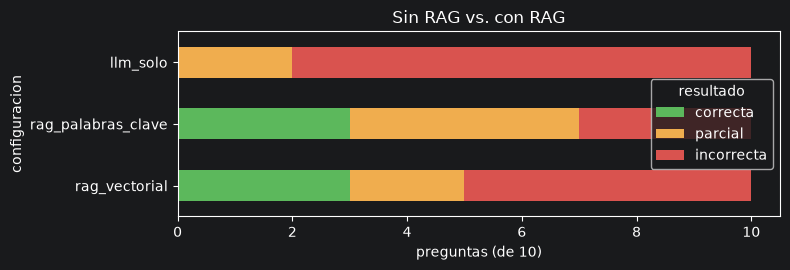

In [17]:
tabla = cmp.resumen(res_llm, res_kw, res_rag)
display(tabla)

ax = tabla[["correcta", "parcial", "incorrecta"]].plot.barh(
    stacked=True, color=["#5cb85c", "#f0ad4e", "#d9534f"], figsize=(8, 2.8))
ax.set_xlabel("preguntas (de 10)"); ax.set_title("Sin RAG vs. con RAG"); ax.invert_yaxis()
plt.tight_layout(); plt.savefig("../salidas/ej1_sin_vs_con_rag.png", dpi=120); plt.show()

In [18]:
# ¿En qué tipo de pregunta acierta el RAG vectorial?
res_rag.groupby("tipo").resultado.value_counts().unstack(fill_value=0)

resultado,correcta,parcial,incorrecta
tipo,,,
agregacion,0,0,1
conteo,0,0,1
descriptiva,1,0,0
en_vivo,1,0,0
filtro,0,1,0
opinion,0,0,1
puntual,1,0,0
ranking,0,0,2
relacional,0,1,0


## Discusión

- **Sin RAG** el modelo no tiene acceso al catálogo: o se niega o inventa. El tamaño del modelo no
  arregla esto: uno más grande suena más convincente, pero sigue sin conocer los datos de la tienda.
- **Con RAG** acierta en las preguntas **descriptivas y puntuales** (qué productos hay, cuánto
  cuesta uno, su stock): la respuesta está escrita en uno o dos documentos y basta con recuperarlos.
- **Palabras clave vs. embeddings:** en este banco empatan porque las preguntas usan los nombres del
  catálogo. La ventaja de los embeddings aparece con paráfrasis (sección 6), que es como suelen
  preguntar los clientes reales.
- El RAG **falla en conteos, agregaciones y rankings** ("¿cuántos productos tienen stock < 5?",
  "¿qué país vende más?"): la respuesta no está en ningún documento, hay que **calcularla** sobre
  todos los datos. Recuperar 7 documentos de 200 no alcanza. Esto motiva el Ejercicio 2.
- La pregunta de **stock en vivo** se responde con el dato del momento del scraping: el índice
  envejece. Esto motiva el Ejercicio 3 (MCP).
- Con un modelo de 0.5B parámetros, parte de los errores es de **generación** aunque la
  recuperación sea correcta: conviene revisar siempre las fuentes recuperadas.

## Trabajo adicional

1. **Filtros automáticos:** detectar en la pregunta una subcategoría y un precio máximo con
   expresiones regulares y pasarlos como `where` a ChromaDB. ¿Mejora la pregunta 2?
2. Cambiar `MODELO_LLM` a `Qwen/Qwen2.5-1.5B-Instruct`: ¿qué errores desaparecen y cuáles no?